In [1]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Student & GitHub Metadata
student_name = "Gerald Angelo Q. Cabiles"
student_id = "TUPM-26-1094"
github_username = "Cyberssaain"

# Deterministic colors derived from last 3 digits of student ID
id_num = int(student_id[-3:])
color1 = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"
color2 = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"

print(f"Student: {student_name} | ID: {student_id} | GitHub: {github_username}")
print(f"Generated Colors -> color1: {color1} | color2: {color2}")

# Locate CSV inside ./spotify_dataset
csv_matches = glob.glob(os.path.join("spotify_dataset", "*.csv"))
if not csv_matches:
    raise FileNotFoundError("No .csv file found inside ./spotify_dataset. Please place the dataset CSV there first.")

dataset_path = csv_matches[0]
print("Using dataset:", dataset_path)

# Load dataset and extract year / decade
df = pd.read_csv(dataset_path, encoding="utf-8")
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year
df["release_year"] = df["year"]
df["decade"] = (df["release_year"] // 10) * 10

print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
df.head(3)

Student: Gerald Angelo Q. Cabiles | ID: TUPM-26-1094 | GitHub: Cyberssaain
Generated Colors -> color1: #921ad6 | color2: #bc4e78
Using dataset: spotify_dataset\spotify_top_1000_tracks.csv
Dataset shape: (1000, 11)
Columns: ['track_name', 'artist', 'album', 'release_date', 'popularity', 'spotify_url', 'id', 'duration_min', 'year', 'release_year', 'decade']


,track_name,artist,album,release_date,popularity,spotify_url,id,duration_min,year,release_year,decade
0,All The Stars (with SZA),Kendrick Lamar,Black Panther The Album Music From And Inspire...,2018-02-09,95,https://open.spotify.com/track/3GCdLUSnKSMJhs4...,3GCdLUSnKSMJhs4Tj6CV3s,3.869767,2018.0,2018.0,2010.0
1,Starboy,The Weeknd,Starboy,2016-11-25,90,https://open.spotify.com/track/7MXVkk9YMctZqd1...,7MXVkk9YMctZqd1Srtv4MB,3.840883,2016.0,2016.0,2010.0
2,Señorita,Shawn Mendes,Señorita,2019-06-21,80,https://open.spotify.com/track/0TK2YIli7K1leLo...,0TK2YIli7K1leLovkQiNik,3.182667,2019.0,2019.0,2010.0


In [2]:
# Clean text columns safely if present
for col in ["track_name", "artist", "album"]:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

# Convert year and decade cleanly
df["year"] = df["year"].fillna(0).astype(int)
df["release_year"] = df["release_year"].fillna(0).astype(int)
df["decade"] = df["decade"].fillna(0).astype(int)

# Drop unnecessary columns if they exist
cols_to_drop = [
    c for c in ["spotify_url", "id", "release_date", "time_signature", "key", "mode"]
    if c in df.columns
]
df = df.drop(columns=cols_to_drop, errors="ignore")

# Feature Engineering: Tempo Category (if 'tempo' column exists)
tempo_bins = [0, 100, 140, np.inf]
tempo_labels = ["Slow", "Medium", "Fast"]
if "tempo" in df.columns:
    df["tempo_category"] = pd.cut(df["tempo"], bins=tempo_bins, labels=tempo_labels, right=False)
    print("Feature 'tempo_category' created.")
else:
    print("Warning: 'tempo' column not found; skipping 'tempo_category' creation.")

# Deduplicate by track_name and artist if both exist
dedup_cols = [c for c in ["track_name", "artist"] if c in df.columns]
if dedup_cols:
    df = df.drop_duplicates(subset=dedup_cols, keep="first").reset_index(drop=True)

print("Data cleaning and feature engineering complete.")
print(f"Final Row Count after deduplication: {len(df)}")

Data cleaning and feature engineering complete.
Final Row Count after deduplication: 971


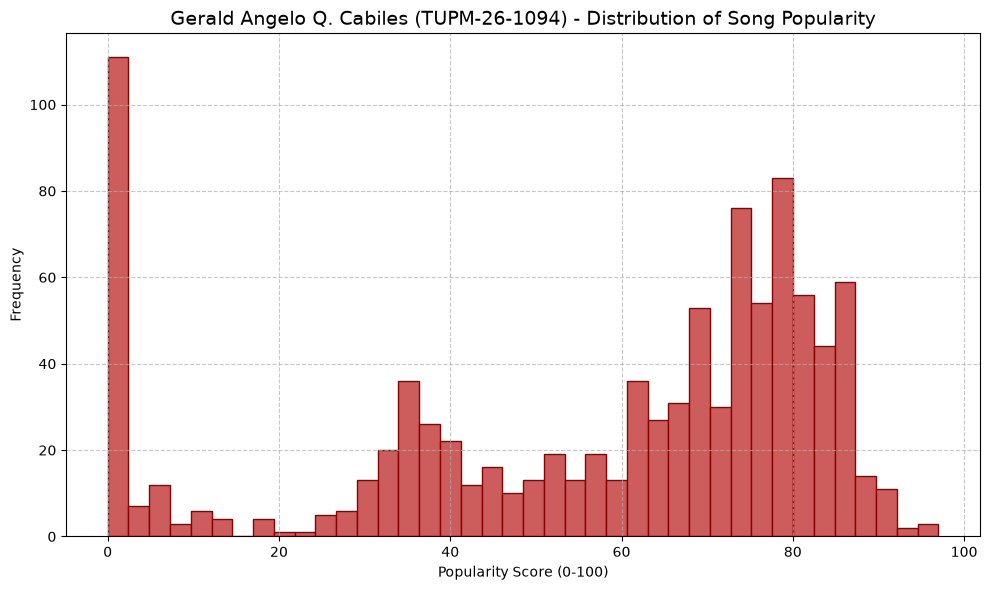

In [3]:
plt.figure(figsize=(10, 6))
plt.hist(df["popularity"].dropna(), bins=40, color="indianred", edgecolor="darkred")
plt.title(f"{student_name} ({student_id}) - Distribution of Song Popularity", fontsize=14)
plt.xlabel("Popularity Score (0-100)")
plt.ylabel("Frequency")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

C:\Users\Archie\AppData\Local\Temp\ipykernel_35144\1325990098.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="year", y="popularity", data=df, palette="viridis")


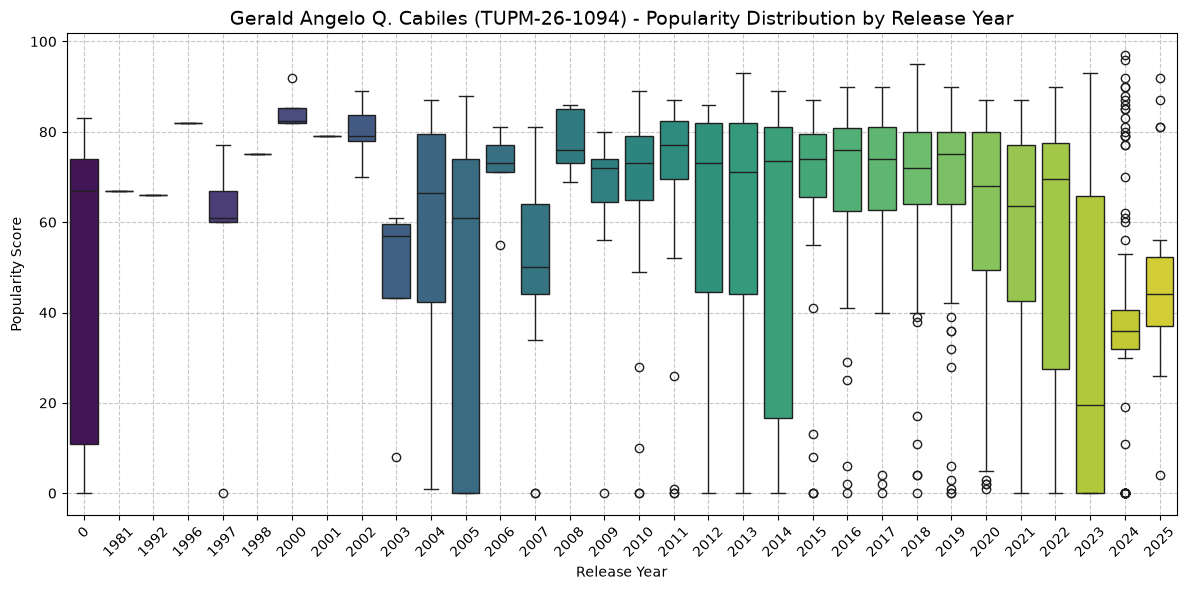

In [4]:
plt.figure(figsize=(12, 6))
sns.boxplot(x="year", y="popularity", data=df, palette="viridis")
plt.title(f"{student_name} ({student_id}) - Popularity Distribution by Release Year", fontsize=14)
plt.xlabel("Release Year")
plt.ylabel("Popularity Score")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

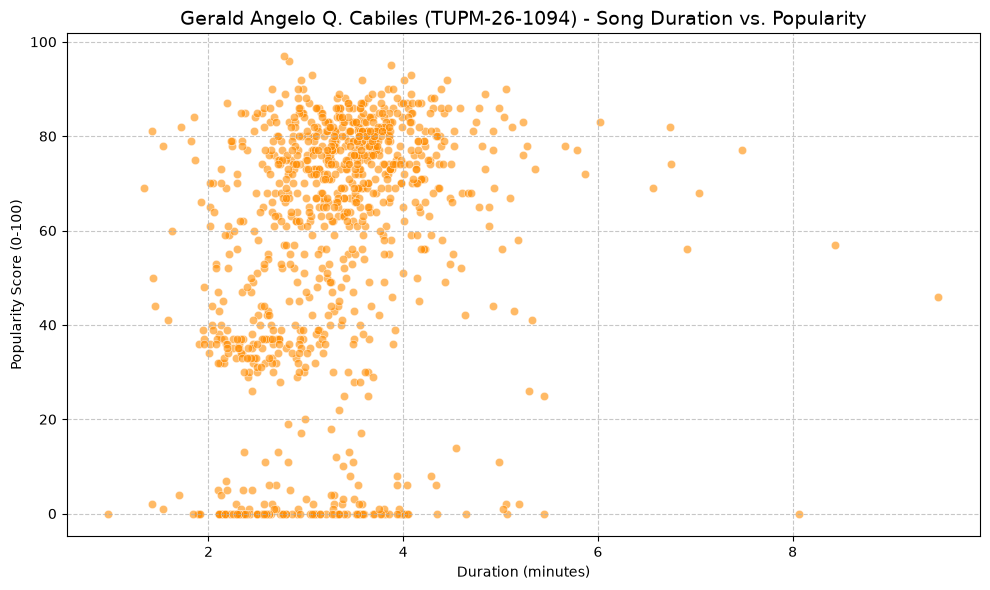

In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="duration_min", y="popularity", data=df, alpha=0.6, color="darkorange")
plt.title(f"{student_name} ({student_id}) - Song Duration vs. Popularity", fontsize=14)
plt.xlabel("Duration (minutes)")
plt.ylabel("Popularity Score (0-100)")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

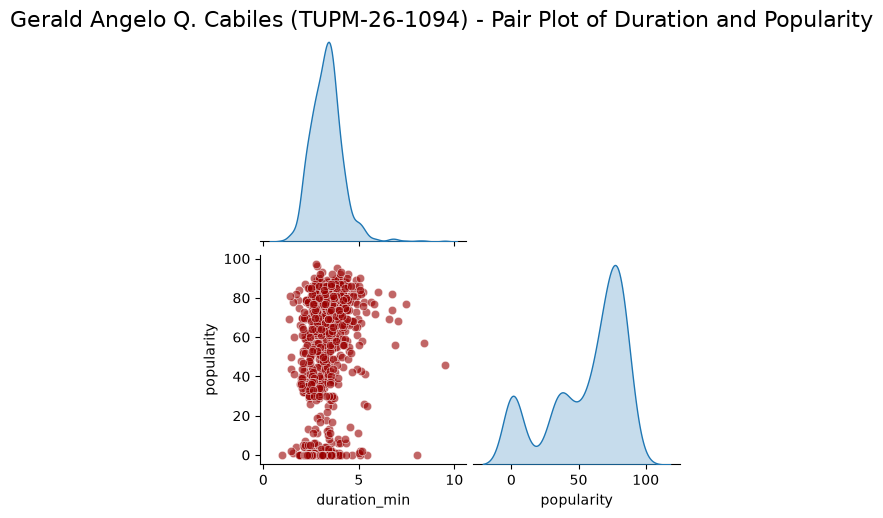

In [6]:
key_features = ["duration_min", "popularity"]
g = sns.pairplot(
    df[key_features].dropna(),
    diag_kind="kde",
    corner=True,
    plot_kws={"alpha": 0.6, "color": "#990000"}
)
g.fig.suptitle(f"{student_name} ({student_id}) - Pair Plot of Duration and Popularity", y=1.02, fontsize=16)
plt.show()

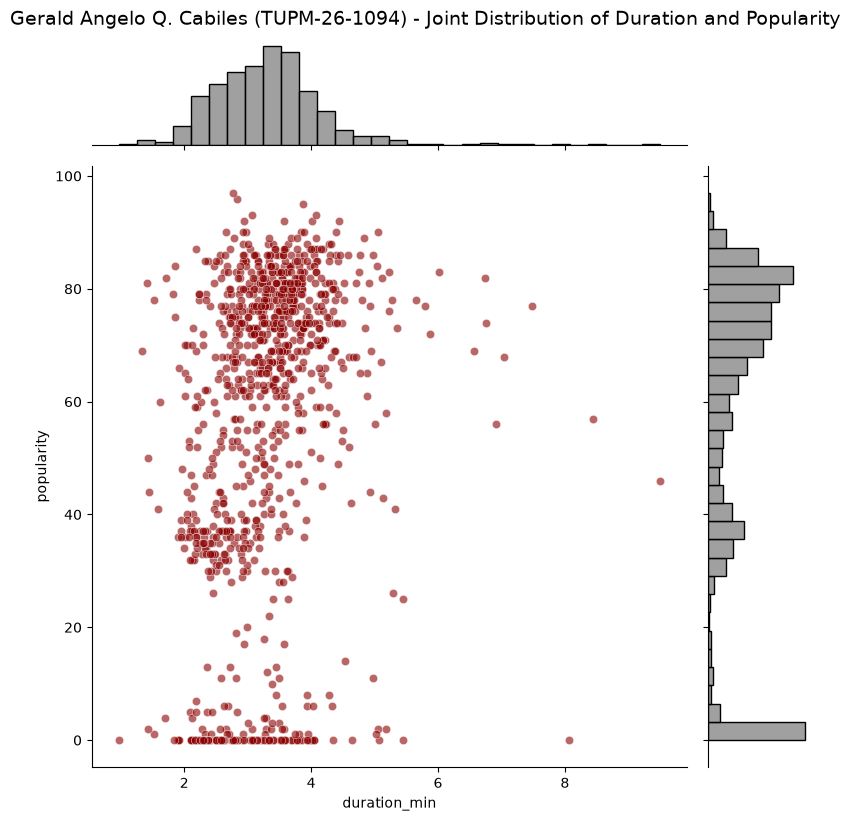

In [7]:
g = sns.jointplot(
    x="duration_min",
    y="popularity",
    data=df.dropna(subset=["duration_min", "popularity"]),
    kind="scatter",
    height=8,
    marginal_kws={"bins": 30, "color": "gray", "edgecolor": "black"},
    joint_kws={"alpha": 0.6, "color": "darkred"}
)
g.fig.suptitle(f"{student_name} ({student_id}) - Joint Distribution of Duration and Popularity", y=1.02, fontsize=14)
plt.show()

In [8]:
import webbrowser
from matplotlib.animation import FuncAnimation, PillowWriter

yearly_popularity = (
    df.dropna(subset=["year", "popularity"])
    .loc[df["year"] > 0]
    .groupby("year")["popularity"]
    .mean()
    .reset_index()
    .sort_values("year")
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(yearly_popularity["year"].min(), yearly_popularity["year"].max())
ax.set_ylim(0, yearly_popularity["popularity"].max() * 1.1)
(line,) = ax.plot([], [], color="royalblue", linewidth=2.5, label="Average Popularity")
ax.set_title(f"{student_name} ({student_id}) - Evolution of Track Popularity Over Time", fontsize=14, color="navy")
ax.set_xlabel("Year of Release", fontsize=12)
ax.set_ylabel("Average Popularity", fontsize=12)
ax.legend(loc="upper left")
plt.tight_layout()

def animate(i):
    x = yearly_popularity["year"].iloc[:i]
    y = yearly_popularity["popularity"].iloc[:i]
    line.set_data(x, y)
    return (line,)

ani = FuncAnimation(fig, animate, frames=len(yearly_popularity) + 1, interval=100, repeat=False)
gif_path = os.path.abspath("yearly_popularity_trend_Cabiles.gif")
ani.save(gif_path, writer=PillowWriter(fps=10))
print(f"GIF saved successfully at: {gif_path}")
webbrowser.open(f"file://{gif_path}")
plt.close(fig)

GIF saved successfully at: c:\Users\Archie\Downloads\Comprog_#1\Lab8_DataVisualization_Cabiles\yearly_popularity_trend_Cabiles.gif


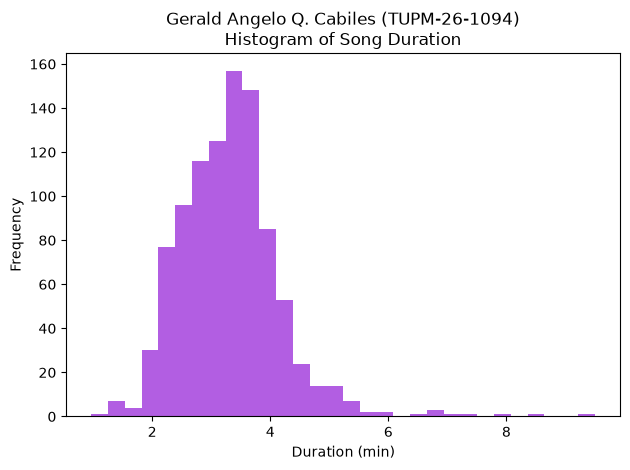

In [9]:
df["duration_min"].plot(kind="hist", bins=30, color=color1, alpha=0.7)
plt.title(f"{student_name} ({student_id})\nHistogram of Song Duration")
plt.xlabel("Duration (min)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

C:\Users\Archie\AppData\Local\Temp\ipykernel_35144\640562075.py:1: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  df["release_year"] = pd.to_datetime(df["year"], format="%Y", errors="coerce").dt.year
C:\Users\Archie\AppData\Local\Temp\ipykernel_35144\640562075.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="decade", y="popularity", data=df, palette="coolwarm")


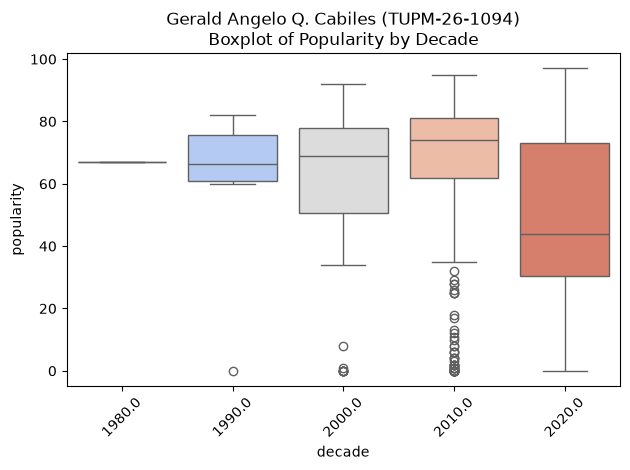

In [10]:
df["release_year"] = pd.to_datetime(df["year"], format="%Y", errors="coerce").dt.year
df["decade"] = (df["release_year"] // 10) * 10
sns.boxplot(x="decade", y="popularity", data=df, palette="coolwarm")
plt.title(f"{student_name} ({student_id})\nBoxplot of Popularity by Decade")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Available columns: ['track_name', 'artist', 'album', 'popularity', 'duration_min', 'year', 'release_year', 'decade']


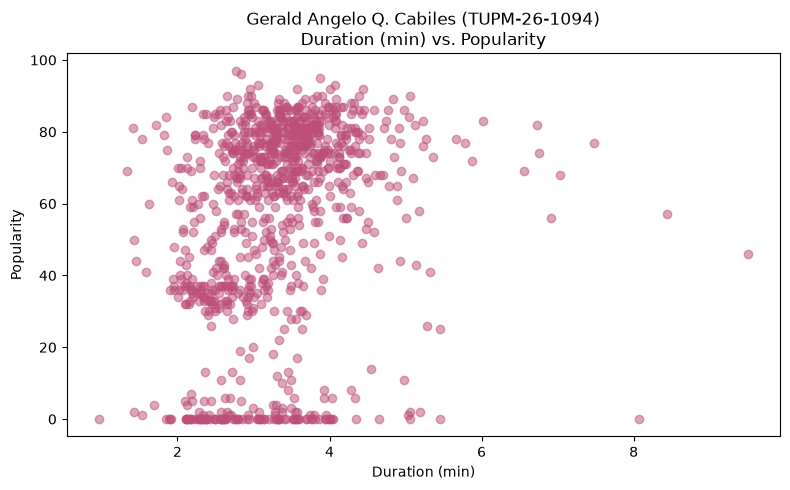

In [12]:
print("Available columns:", list(df.columns))

x_col = "tempo" if "tempo" in df.columns else "duration_min"
x_label = "Tempo (BPM)" if x_col == "tempo" else "Duration (min)"

plt.figure(figsize=(8, 5))
plt.scatter(df[x_col], df["popularity"], alpha=0.5, color=color2)
plt.title(f"{student_name} ({student_id})\n{x_label} vs. Popularity")
plt.xlabel(x_label)
plt.ylabel("Popularity")
plt.tight_layout()
plt.show()

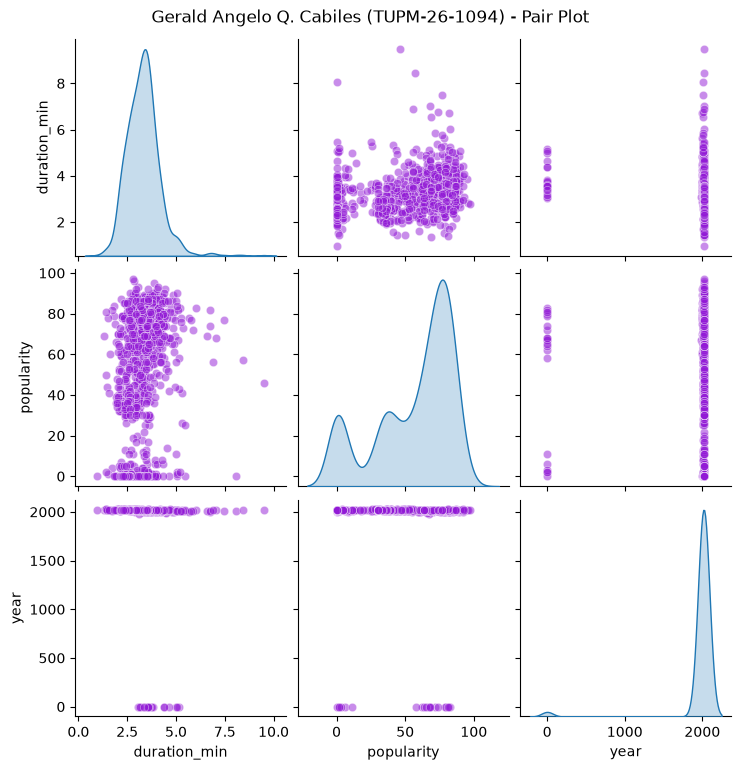

In [13]:
candidate_cols = ["duration_min", "popularity", "tempo", "year"]
plot_cols = [c for c in candidate_cols if c in df.columns]

sns.pairplot(
    df[plot_cols].dropna(),
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "color": color1}
)
plt.suptitle(f"{student_name} ({student_id}) - Pair Plot", y=1.02)
plt.show()

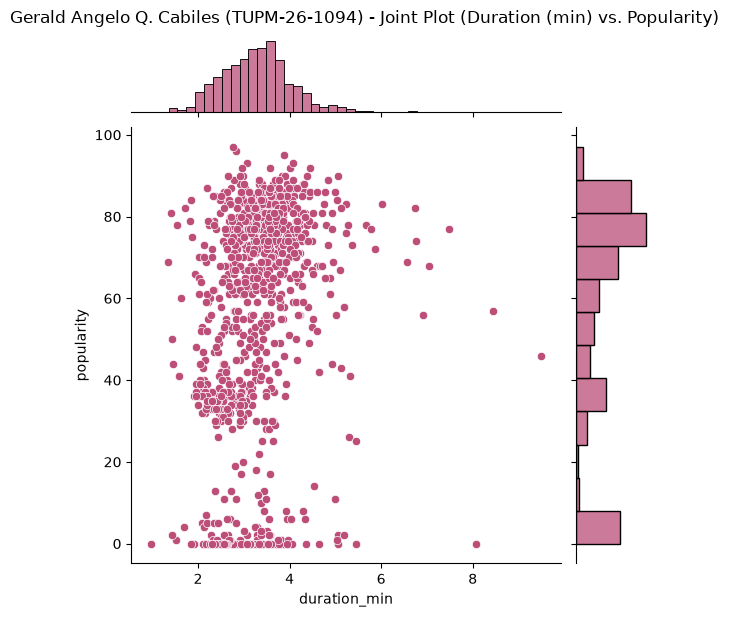

In [14]:
x_col = "tempo" if "tempo" in df.columns else "duration_min"
x_label = "Tempo (BPM)" if x_col == "tempo" else "Duration (min)"

g = sns.jointplot(
    x=x_col,
    y="popularity",
    data=df.dropna(subset=[x_col, "popularity"]),
    kind="scatter",
    color=color2
)
g.fig.suptitle(f"{student_name} ({student_id}) - Joint Plot ({x_label} vs. Popularity)", y=1.02)
plt.show()

In [15]:
import webbrowser
from matplotlib.animation import FuncAnimation, PillowWriter

metric_col = (
    "tempo"
    if "tempo" in df.columns
    else ("duration_min" if "duration_min" in df.columns else "popularity")
)
metric_label = (
    "Tempo (BPM)"
    if metric_col == "tempo"
    else ("Duration (min)" if metric_col == "duration_min" else "Popularity")
)

yearly_metric = (
    df.dropna(subset=["year", metric_col])
    .loc[df["year"] > 0]
    .groupby("year")[metric_col]
    .mean()
    .reset_index()
    .sort_values("year")
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlim(yearly_metric["year"].min(), yearly_metric["year"].max())
ax.set_ylim(0, yearly_metric[metric_col].max() * 1.15)
(line,) = ax.plot([], [], color=color1, linewidth=2.5, marker="o", markersize=4, label=f"Mean {metric_label}")
ax.set_title(f"{student_name} ({student_id})\nAnimated {metric_label} Trend by Year")
ax.set_xlabel("Release Year")
ax.set_ylabel(f"Average {metric_label}")
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper left")
plt.tight_layout()

def animate(i):
    x = yearly_metric["year"].iloc[:i]
    y = yearly_metric[metric_col].iloc[:i]
    line.set_data(x, y)
    return (line,)

ani = FuncAnimation(fig, animate, frames=len(yearly_metric) + 1, interval=120, repeat=False)
snippet6_gif = os.path.abspath(f"snippet6_{metric_col}_trend_Cabiles.gif")
ani.save(snippet6_gif, writer=PillowWriter(fps=10))
print(f"GIF saved successfully at: {snippet6_gif}")
webbrowser.open(f"file://{snippet6_gif}")
plt.close(fig)

GIF saved successfully at: c:\Users\Archie\Downloads\Comprog_#1\Lab8_DataVisualization_Cabiles\snippet6_duration_min_trend_Cabiles.gif


Lab 8 Observations Summary — Gerald Angelo Q. Cabiles (TUPM-26-1094)

Popularity Distribution: Song popularity scores in the top tracks dataset cluster heavily in the upper range, showing how top-performing tracks concentrate around higher popularity values.

Release Year & Decade Trends: Grouping tracks by release year and decade highlights shifts in popularity spread, medians, and outliers across eras.

Duration & Feature Relationships: Comparing song duration (duration_min) against popularity via scatter, pair, and joint plots reveals that most tracks fall within a standard song-length window with varying popularity scores.

Temporal Evolution: The animated trend charts visualize how yearly averages shift progressively over time and export cleanly as GIF animations.